# 프로젝트 1: PVD AlCu 데이터 이해와 탐색적 분석

데이터의 구조와 품질을 확인하고, 17개 출력값의 행별 요약과 센서와의 관계를 탐색합니다.

## 1. 프로젝트 목표

AlCu 박막 증착 공정에서 설비 센서와 두께의 관계를 살펴보고, 평균 두께와 웨이퍼 내 산포를 설명할 수 있는 변수를 탐색합니다. 이후 회귀분석과 추가 실험 설계로 이어갑니다.

## 2. 데이터 출처와 파일

[Zenodo: Advanced Process Control and Statistical Process Control Data for Thickness Prediction of AlCu and WTi Metal Layer](https://zenodo.org/records/16881338)에서 공개한 실제 반도체 제조 PVD 공정 데이터 중 AlCu 파일을 사용합니다. 원 출처는 Infineon Technologies의 공정 데이터입니다.

| 파일 | 역할 | 확인한 크기 |
|---|---|---|
| `../datasets/pvd_alcu/X_pvd_AlCu.csv` | 공정 중 설비 센서 집계값 | 4,848행 × 97열 |
| `../datasets/pvd_alcu/Y_pvd_AlCu.csv` | 공정 후 17개 지점의 두께 측정값 | 4,848행 × 17열 |

행과 열의 개수는 이 저장소에 내려받은 CSV에서 헤더를 제외하고 확인했습니다. 경로는 노트북이 있는 폴더를 기준으로 표시했습니다. 데이터셋과 관련 논문의 인용 정보는 원본 페이지를 참고하세요.

## 3. 입력 데이터 X: 공정 센서

`Sensor_1`부터 `Sensor_97`까지 97개 열이 있습니다. 원본 설명에 따르면 가스 유량, 온도, 전압, 전류 등 장비 내부 센서 시계열을 집계한 값입니다. 공정 중 상태를 나타내는 입력 변수로 사용할 예정입니다.

**주의:** 열 이름이 익명화되어 있어 각 번호가 어떤 물리량인지, 단위가 무엇인지 이 파일만으로는 알 수 없습니다. 센서값은 측정된 공정 상태이며, 실제로 직접 조절 가능한 레시피 설정값인지 확인되지 않았습니다.

## 4. 출력 데이터 Y: 두께 측정

`RAW_VALUE_t_1`부터 `RAW_VALUE_t_17`까지 17개 열이 있습니다. 원본 설명상 각 열은 두께 측정 지점에 해당합니다. 한 행의 17개 값을 함께 살펴보면 해당 관측의 평균 두께와 지점 간 산포를 계산할 수 있습니다.

예를 들어 평균은 17개 값의 합을 17로 나눈 값이고, 표준편차는 그 값들이 평균에서 얼마나 퍼져 있는지 나타냅니다. Uniformity는 여러 정의가 가능하므로 실제 분석 전에 식을 정하고 명시해야 합니다.

측정값의 **물리 단위, 스케일 변환 여부, 각 지점의 웨이퍼상 위치**는 현재 확인되지 않았습니다. 값이 0과 1 사이로 보이더라도 정규화 방식이나 실제 두께 단위를 추정하면 안 됩니다. 공간 패턴이나 실제 규격과의 비교에는 추가 정보가 필요합니다.

## 5. X와 Y를 어떻게 함께 볼까?

X와 Y는 각각 4,848행으로 크기가 같습니다. 원본은 입력과 출력을 분리하여 제공하지만, CSV 열에는 명시적인 관측 ID가 없습니다. **행 수가 같다는 사실만으로 행 순서가 정확히 대응한다는 것이 증명되지는 않습니다.** 모델링 전에 원본 문서나 제공자 정보를 통해 매칭 기준과 각 행의 단위(예: 웨이퍼 또는 다른 생산 단위)를 확인해야 합니다.

대응이 확인되면 하나의 관측에 대해 센서 97개를 입력으로 두고, 17개 두께값 또는 그 요약 지표를 결과로 분석할 수 있습니다. 확인되지 않으면 행 순서 매칭은 가정임을 밝히고 결과 해석을 제한합니다.

## 6. 앞으로 확인할 질문

1. X와 Y의 행은 어떤 기준으로 연결되며 한 행은 무엇을 뜻하는가?
2. 결측값, 상수 열, 중복 행, 비정상적인 값이 있는가?
3. 17개 측정값의 단위와 변환 방식은 무엇인가? 지점 배치는 알려져 있는가?
4. 평균 두께와 산포는 어떤 센서 변수와 관련이 있는가? 변수끼리도 강한 상관이 있는가?
5. 시간, 설비, Lot, Recipe 정보가 제공되는가? 평가 시 데이터 누출을 어떻게 방지할 수 있는가?
6. 실제로 조절 가능한 변수와 실험군 정보가 있는가? 없다면 어떤 추가 Split 실험이 필요한가?

## 7. 해석 범위

이 데이터는 센서와 두께의 **관계와 예측 가능성**을 탐색하기에 적합합니다. 관측된 상관관계나 회귀계수만으로 변수 변경의 인과효과를 확정할 수는 없습니다. 계획된 Split 실험, 제어 가능한 조건과 실제 공정 규격이 확인되기 전에는 결과를 현장에 적용할 최적 레시피로 간주하지 않습니다.

아래에서 데이터를 불러와 기초 품질과 분포를 확인합니다.

---
## 8. EDA 목표와 진행 순서

**데이터 확인 → 품질 점검 → Y의 행별 지표 → 분포 → 센서와의 관계 → 센서 간 관계 → 결과 정리** 순서로 진행합니다. 각 단계에서 계산을 하는 이유와 결과를 읽는 방법을 함께 설명합니다.

### 분석에 필요한 가정

- 원본은 X와 Y를 입력·출력 파일 쌍으로 제공하지만 CSV에는 연결 ID가 없습니다. 아래 관계 분석은 **두 파일이 같은 행 순서로 대응한다는 가정** 아래 진행하는 조건부 탐색입니다. 행 수가 같다는 사실만으로 대응이 증명되지는 않습니다.


-> 대응이 되지 않는다는 문제는 주의할 필요가 있다. 


- 논문은 AlCu의 4,848개 관측을 웨이퍼 수로 설명합니다. 다만 각 Y 열의 단위와 변환 방법, 특히 열별로 다른 변환이 적용되었는지는 확인하지 못했습니다. 따라서 값은 **제공된 척도**로 보고, 17개 값의 평균·표준편차·범위는 행별 요약값으로 해석합니다. 공통 물리 척도가 확인되기 전에는 이를 실제 두께나 웨이퍼 내 물리적 산포로 확정하지 않습니다.
- 상관관계는 함께 변하는 정도를 보여주며 조건을 바꾸었을 때의 인과효과를 입증하지 않습니다.

출처: [Zenodo 원본](https://zenodo.org/records/16881338), [관련 논문](https://doi.org/10.3233/FAIA251482).

### 8-1. 분석 환경 준비

`pandas`는 표를 다루고, `numpy`는 수치 검사를, `matplotlib`과 `seaborn`은 분포와 관계를 보여주는 그래프를 그립니다. 노트북 폴더 또는 저장소 루트에서 실행할 수 있도록 데이터 폴더를 찾습니다.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import matplotlib.font_manager as fm
import seaborn as sns
from IPython.display import display, Markdown

# 한국어 폰트가 있으면 사용하고, 없으면 기본 글꼴로 표시합니다.
font_paths = [
    Path('/System/Library/Fonts/Supplemental/AppleGothic.ttf'),
    Path('/usr/share/fonts/truetype/nanum/NanumGothic.ttf'),
    Path('C:/Windows/Fonts/malgun.ttf'),
]
for font_path in font_paths:
    if font_path.exists():
        fm.fontManager.addfont(str(font_path))
        plt.rcParams['font.family'] = fm.FontProperties(fname=str(font_path)).get_name()
        break
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', font=plt.rcParams['font.family'][0], rc={'axes.unicode_minus': False})
pd.set_option('display.max_columns', 15)
pd.set_option('display.float_format', '{:.4f}'.format)

# 현재 폴더 또는 상위 폴더에서 저장소의 datasets 디렉터리를 찾습니다.
search_roots = [Path.cwd(), *Path.cwd().parents]
data_dir = next((root / 'datasets' / 'pvd_alcu' for root in search_roots
                 if (root / 'datasets' / 'pvd_alcu').is_dir()), None)
if data_dir is None:
    raise FileNotFoundError('datasets/pvd_alcu 폴더를 찾지 못했습니다. 저장소 안에서 실행해 주세요.')
print(f'입력 폴더: {data_dir}')

입력 폴더: /Users/minnong511/code_repository/Semi_Conductor_Projects/datasets/pvd_alcu


## 9. 데이터 구조 확인

**왜?** 분석 단위와 열을 확인해야 두 파일을 잘못 합치거나, 센서와 측정값을 혼동하지 않습니다. 행 수·열 이름·자료형과 일부 값을 확인합니다.

In [2]:
X_raw = pd.read_csv(data_dir / 'X_pvd_AlCu.csv')
Y_raw = pd.read_csv(data_dir / 'Y_pvd_AlCu.csv')
print(f'X: {X_raw.shape[0]:,}행 × {X_raw.shape[1]}열')
print(f'Y: {Y_raw.shape[0]:,}행 × {Y_raw.shape[1]}열')
print('X의 앞 3개 열:', ', '.join(X_raw.columns[:3]))
print('Y의 전체 열:', ', '.join(Y_raw.columns))
print('X 자료형별 열 수:')
display(X_raw.dtypes.astype(str).value_counts().rename('열 수').to_frame())
print('Y 자료형별 열 수:')
display(Y_raw.dtypes.astype(str).value_counts().rename('열 수').to_frame())
print('X 앞 3행, 앞 5개 센서:')
display(X_raw.iloc[:3, :5])
print('Y 앞 3행, 앞 5개 측정 지점:')
display(Y_raw.iloc[:3, :5])
if len(X_raw) != len(Y_raw):
    raise ValueError('X와 Y의 행 수가 달라 행 순서 가정으로 연결할 수 없습니다.')
print('행 수 일치: 연결의 필요조건이며 대응 관계를 보증하지는 않습니다.')

X: 4,848행 × 97열
Y: 4,848행 × 17열
X의 앞 3개 열: Sensor_1, Sensor_2, Sensor_3
Y의 전체 열: RAW_VALUE_t_1, RAW_VALUE_t_2, RAW_VALUE_t_3, RAW_VALUE_t_4, RAW_VALUE_t_5, RAW_VALUE_t_6, RAW_VALUE_t_7, RAW_VALUE_t_8, RAW_VALUE_t_9, RAW_VALUE_t_10, RAW_VALUE_t_11, RAW_VALUE_t_12, RAW_VALUE_t_13, RAW_VALUE_t_14, RAW_VALUE_t_15, RAW_VALUE_t_16, RAW_VALUE_t_17
X 자료형별 열 수:


,열 수
float64,97


Y 자료형별 열 수:


,열 수
float64,17


X 앞 3행, 앞 5개 센서:


,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5
0,0.1092,0.2350,0.3543,0.1408,0.3121
1,0.0921,0.2489,0.3745,0.1232,0.3303
2,0.1226,0.2548,0.3866,0.1536,0.3387


Y 앞 3행, 앞 5개 측정 지점:


,RAW_VALUE_t_1,RAW_VALUE_t_2,RAW_VALUE_t_3,RAW_VALUE_t_4,RAW_VALUE_t_5
0,0.7038,0.5825,0.7285,0.6132,0.6517
1,0.7075,0.5837,0.7311,0.6190,0.6575
2,0.7492,0.6195,0.7774,0.6539,0.6928


행 수 일치: 연결의 필요조건이며 대응 관계를 보증하지는 않습니다.


## 10. 데이터 품질 확인

**왜?** 비어 있는 값이나 숫자가 아닌 값은 계산을 방해하고, 변하지 않는 센서는 상관계수를 구할 수 없습니다. 중복은 기록 반복일 수도, 서로 다른 웨이퍼의 동일한 측정값일 수도 있으므로 개수를 확인하되 바로 지우지 않습니다. 표의 중복 수는 **첫 등장 이후의 완전히 같은 행 수**입니다.

In [3]:
# 숫자로 읽을 수 없는 값은 NaN으로 바꿔 개수를 확인합니다. 원본은 유지합니다.
X = X_raw.apply(pd.to_numeric, errors='coerce')
Y = Y_raw.apply(pd.to_numeric, errors='coerce')

def quality_summary(raw, numeric):
    arr = numeric.to_numpy(dtype=float)
    return {
        '행 수': len(raw), '열 수': raw.shape[1],
        '원본 결측 셀': int(raw.isna().sum().sum()),
        '숫자 변환 후 결측 증가': int(numeric.isna().sum().sum() - raw.isna().sum().sum()),
        '무한대 셀': int(np.isinf(arr).sum()),
        '상수 열': int((numeric.nunique(dropna=True) <= 1).sum()),
        '완전 중복 행': int(raw.duplicated().sum()),
    }
quality = pd.DataFrame({'X 센서': quality_summary(X_raw, X), 'Y 측정': quality_summary(Y_raw, Y)})
display(quality)
print('결측값이 있는 열 수: X', int(X.isna().any().sum()), '/ Y', int(Y.isna().any().sum()))
print('상수 센서:', list(X.columns[X.nunique(dropna=True) <= 1]))
print('상수 측정 열:', list(Y.columns[Y.nunique(dropna=True) <= 1]))
paired_duplicates = pd.concat([X.add_prefix('X_'), Y.add_prefix('Y_')], axis=1).duplicated().sum()
print(f'같은 행 위치에서 결합했을 때 X와 Y가 모두 완전히 같은 중복 행: {paired_duplicates:,}개')
# NaN / 무한대는 이후 계산에서 빠진 값으로 취급합니다.
X = X.replace([np.inf, -np.inf], np.nan)
Y = Y.replace([np.inf, -np.inf], np.nan)

,X 센서,Y 측정
행 수,4848,4848
열 수,97,17
원본 결측 셀,0,0
숫자 변환 후 결측 증가,0,0
무한대 셀,0,0
상수 열,0,0
완전 중복 행,0,1203


결측값이 있는 열 수: X 0 / Y 0
상수 센서: []
상수 측정 열: []
같은 행 위치에서 결합했을 때 X와 Y가 모두 완전히 같은 중복 행: 0개


### 10-1. 중복과 특이한 행 자세히 보기

**왜?** Y에 같은 값이 반복되거나 17개 값이 모두 0인 행이 있다면 분포와 상관관계에 영향을 줄 수 있습니다. 실제 오류라고 단정할 근거가 없으므로 원본은 보존하고, 뒤에서 0행 포함·제외를 비교합니다. 행 번호는 데이터프레임의 **0부터 시작하는 인덱스**입니다.

In [4]:
zero_y_mask = Y.notna().all(axis=1) & Y.eq(0).all(axis=1)
zero_y_indices = Y.index[zero_y_mask].tolist()
print(f'Y의 17개 값이 모두 0인 행: {len(zero_y_indices)}개; 인덱스: {zero_y_indices[:20]}')
repeats = Y.value_counts(dropna=False).head(3).rename('동일 행 출현 횟수')
print('Y에서 가장 많이 반복된 행들의 출현 횟수:')
display(repeats.reset_index(drop=True).to_frame())
print('※ 동일한 Y값만으로 동일 웨이퍼나 잘못된 기록이라고 판단하지 않습니다.')

# 가장 자주 나타난 Y 벡터와 같은 행 위치에 놓인 X를 살펴봅니다.
first_repeat = Y.value_counts(dropna=False).index[0]
pattern_mask = Y.eq(pd.Series(first_repeat, index=Y.columns), axis='columns').all(axis=1)
positions = np.flatnonzero(pattern_mask.to_numpy())
print(f'가장 많이 반복된 Y 벡터: {len(positions)}행; 해당 위치 X의 서로 다른 행: {len(X.loc[pattern_mask].drop_duplicates())}개')
if len(positions):
    print(f'해당 인덱스 범위: {positions.min()}–{positions.max()} (0부터 시작); 연속 여부: {bool(np.all(np.diff(positions) == 1))}')
if zero_y_indices:
    for idx in zero_y_indices[:5]:
        print(f'Y가 모두 0인 인덱스 {idx}의 X에서 0인 센서 수: {int(X.loc[idx].eq(0).sum())}')
print('반복의 원인은 데이터만으로 확정하지 않습니다. 같은 행 순서 연결 가정하에 비교했습니다.')

Y의 17개 값이 모두 0인 행: 1개; 인덱스: [2586]
Y에서 가장 많이 반복된 행들의 출현 횟수:


,동일 행 출현 횟수
0,198
1,45
2,44


※ 동일한 Y값만으로 동일 웨이퍼나 잘못된 기록이라고 판단하지 않습니다.
가장 많이 반복된 Y 벡터: 198행; 해당 위치 X의 서로 다른 행: 198개
해당 인덱스 범위: 1678–1875 (0부터 시작); 연속 여부: True
Y가 모두 0인 인덱스 2586의 X에서 0인 센서 수: 14
반복의 원인은 데이터만으로 확정하지 않습니다. 같은 행 순서 연결 가정하에 비교했습니다.


## 11. Y의 17개 값을 행별로 요약

**왜?** 각 관측의 17개 값을 한꺼번에 보면 전반적인 수준과 값의 퍼짐을 비교하기 어렵습니다. 각 행에서 세 지표를 만듭니다.

- **평균:** 17개 값의 합 ÷ 17. 행의 전반적인 수준을 요약합니다.
- **표준편차:** 17개 값이 평균 주위에 얼마나 퍼져 있는지 보여줍니다. 여기서는 표본 표준편차(`ddof=1`)를 사용합니다.
- **범위:** 최댓값 − 최솟값. 가장 멀리 떨어진 두 값의 차이를 보여줍니다.

17개 값이 공통 물리 척도라는 사실은 아직 확인되지 않았으므로 이 수치는 **제공값의 행별 요약**입니다. 일부 지점이 빠진 행은 다른 행과 같은 17점 기준으로 비교할 수 없어 요약에서 결측으로 둡니다.

In [5]:
if Y.shape[1] != 17:
    raise ValueError(f'Y에서 기대한 17개 열 대신 {Y.shape[1]}개 열을 발견했습니다.')
metrics = pd.DataFrame({
    '평균': Y.mean(axis=1, skipna=False),
    '표준편차': Y.std(axis=1, ddof=1, skipna=False),
    '범위': Y.max(axis=1, skipna=False) - Y.min(axis=1, skipna=False),
}, index=Y.index)
print('앞 5개 관측의 Y 요약 (제공된 척도):')
display(metrics.head())
print('관측 전체의 지표별 요약:')
display(metrics.describe().T)
print('17개 값 중 하나 이상이 없어 요약이 비어 있는 행:', int(metrics.isna().any(axis=1).sum()))

앞 5개 관측의 Y 요약 (제공된 척도):


,평균,표준편차,범위
0,0.5844,0.1098,0.3555
1,0.5879,0.1107,0.3601
2,0.6221,0.1173,0.3791
3,0.6219,0.1176,0.3792
4,0.6361,0.1207,0.3902


관측 전체의 지표별 요약:


,count,mean,std,min,25%,50%,75%,max
평균,4848.0000,0.6124,0.0146,0.0000,0.6055,0.6131,0.6192,0.7761
표준편차,4848.0000,0.1150,0.0039,0.0000,0.1128,0.1153,0.1172,0.1501
범위,4848.0000,0.3816,0.0124,0.0000,0.3758,0.3825,0.3879,0.4872


17개 값 중 하나 이상이 없어 요약이 비어 있는 행: 0


## 12. 히스토그램과 박스플롯으로 분포 확인

**왜?** 히스토그램은 값이 어느 구간에 집중되는지, 박스플롯은 중앙값과 사분위수 및 멀리 떨어진 후보를 보여줍니다. 각 지표는 범위가 다르므로 **서로 다른 축**을 사용합니다.

IQR은 3사분위수(Q3) − 1사분위수(Q1)입니다. 아래 표는 Q1 − 1.5×IQR보다 작거나 Q3 + 1.5×IQR보다 큰 행을 **이상치 후보**로 세며, 오류나 불량으로 판정하거나 자동 삭제하지 않습니다.

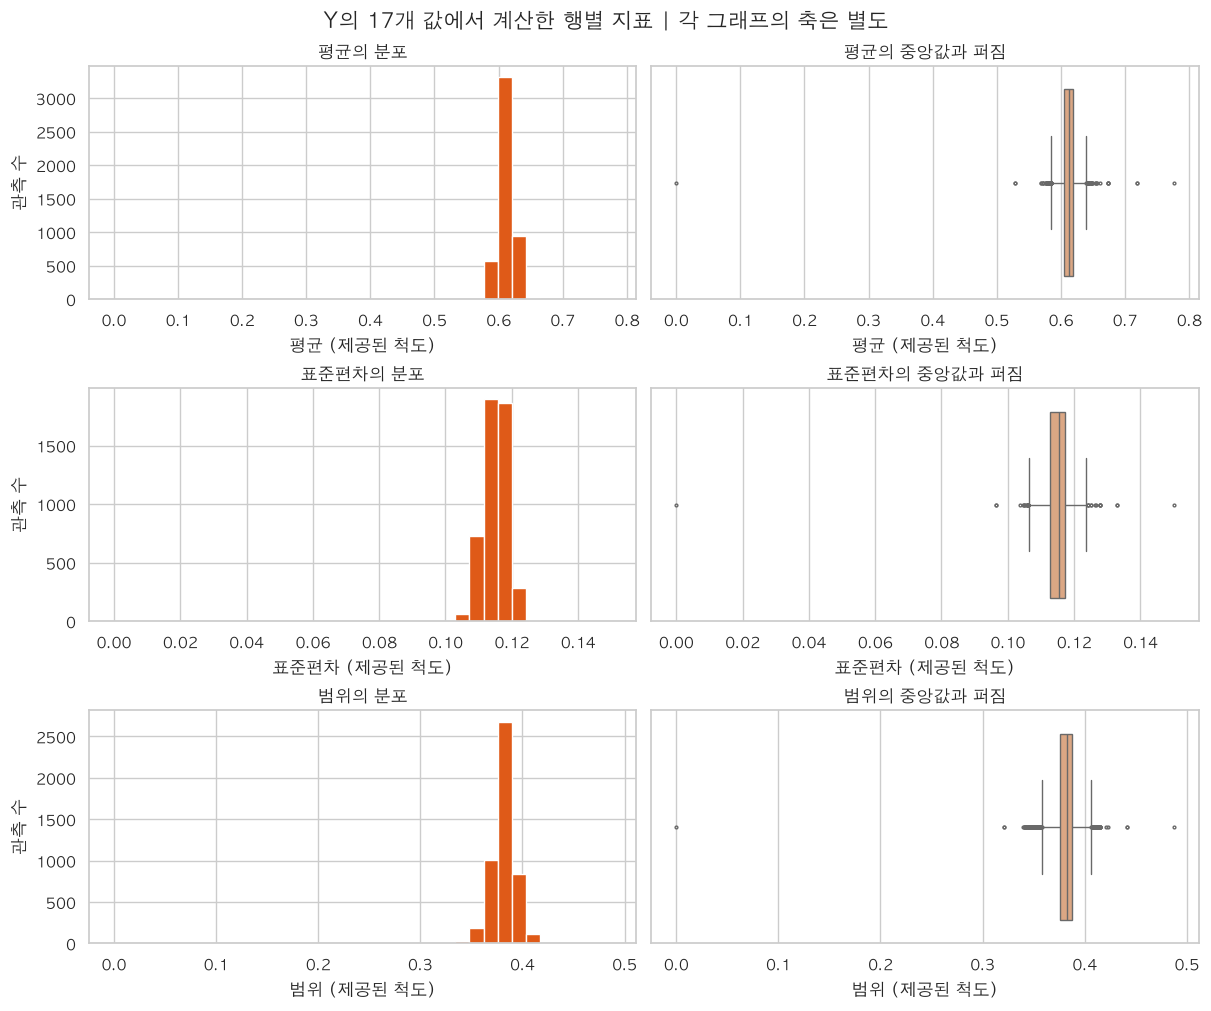

,Q1,중앙값,Q3,하한,상한,후보 수,관측 수
지표,,,,,,,
평균,0.6055,0.6131,0.6192,0.5849,0.6398,78,4848
표준편차,0.1128,0.1153,0.1172,0.1063,0.1238,36,4848
범위,0.3758,0.3825,0.3879,0.3577,0.4060,202,4848


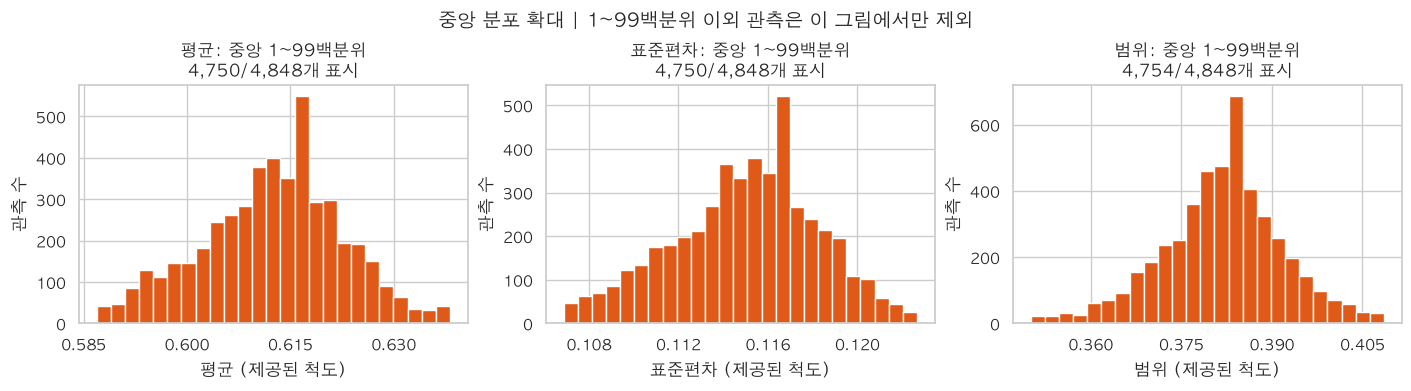

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10), constrained_layout=True)
for row, name in enumerate(metrics.columns):
    values = metrics[name].dropna()
    axes[row, 0].hist(values, bins=35, color='#df5a18', edgecolor='white')
    axes[row, 0].set(title=f'{name}의 분포', xlabel=f'{name} (제공된 척도)', ylabel='관측 수')
    sns.boxplot(x=values, ax=axes[row, 1], color='#e9a476', fliersize=2)
    axes[row, 1].set(title=f'{name}의 중앙값과 퍼짐', xlabel=f'{name} (제공된 척도)', yticks=[])
fig.suptitle('Y의 17개 값에서 계산한 행별 지표 | 각 그래프의 축은 별도', fontsize=15)
plt.show()

iqr_rows = []
for name in metrics.columns:
    v = metrics[name].dropna()
    q1, q3 = v.quantile([.25, .75]); iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    mask = (v < low) | (v > high)
    iqr_rows.append({'지표': name, 'Q1': q1, '중앙값': v.median(), 'Q3': q3,
                     '하한': low, '상한': high, '후보 수': int(mask.sum()), '관측 수': len(v)})
iqr_summary = pd.DataFrame(iqr_rows).set_index('지표')
display(iqr_summary)

# 전체 분포에서 0행과 극단값 때문에 중앙 구간이 좁게 보일 수 있어
# 1~99백분위 구간을 별도로 확대합니다. 데이터나 앞의 전체 분포는 바꾸지 않습니다.
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
for ax, name in zip(axes, metrics.columns):
    values = metrics[name].dropna()
    lo, hi = values.quantile([.01, .99])
    visible = values[(values >= lo) & (values <= hi)]
    ax.hist(visible, bins=25, color='#df5a18', edgecolor='white')
    ax.set(title=f'{name}: 중앙 1~99백분위\n{len(visible):,}/{len(values):,}개 표시', xlabel=f'{name} (제공된 척도)', ylabel='관측 수')
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
fig.suptitle('중앙 분포 확대 | 1~99백분위 이외 관측은 이 그림에서만 제외', fontsize=14)
plt.show()

## 13. 센서와 행별 요약의 관계

**왜?** 센서 중 어떤 변수가 출력의 전반적 수준 또는 퍼짐과 함께 움직이는지 파악하면 후속 회귀분석에서 살펴볼 후보를 좁힐 수 있습니다.

두 파일이 같은 순서로 대응한다고 **가정**하고, Pearson 상관계수 `r`을 계산합니다. `r`은 −1에서 +1 사이이며 부호는 선형 관계의 방향, 절댓값은 선형 관계의 강도를 나타냅니다. 관계가 비선형이거나 일부 관측에 민감할 수 있으므로 상위 센서의 산점도도 함께 확인합니다. 상관계수를 계산할 수 없는 상수 센서는 순위에서 제외합니다.

여기서 선택한 센서는 전체 데이터의 탐색 결과입니다. 모델 성능을 평가할 때는 먼저 학습·평가 데이터를 나누고 변수 선택은 학습 데이터에서만 수행합니다.

In [7]:
analysis = pd.concat([X.reset_index(drop=True), metrics.reset_index(drop=True)], axis=1)
targets = ['평균', '표준편차']
correlations = pd.DataFrame({name: X.reset_index(drop=True).corrwith(analysis[name], method='pearson')
                             for name in targets})

def top_correlations(frame, target, n=5):
    values = frame[target].dropna()
    return values.loc[values.abs().sort_values(ascending=False).index].head(n).rename('Pearson r').to_frame()

for target in targets:
    print(f'{target}의 절대 상관계수 상위 5개 센서 (조건부 탐색):')
    display(top_correlations(correlations, target))

평균의 절대 상관계수 상위 5개 센서 (조건부 탐색):


,Pearson r
Sensor_40,0.3456
Sensor_39,0.3143
Sensor_79,0.2439
Sensor_80,0.1986
Sensor_33,-0.1827


표준편차의 절대 상관계수 상위 5개 센서 (조건부 탐색):


,Pearson r
Sensor_34,-0.4066
Sensor_89,-0.4057
Sensor_17,-0.3944
Sensor_29,-0.3857
Sensor_27,-0.3812


### 13-1. 상위 센서의 산점도

**왜?** 상관계수 한 숫자만으로는 점들의 모양과 극단적인 값의 영향을 알 수 없습니다. 각 목표의 상위 세 센서에 대해 모든 관측을 점으로 표시합니다. 점이 겹치는 부분이 보이도록 투명도를 사용합니다.

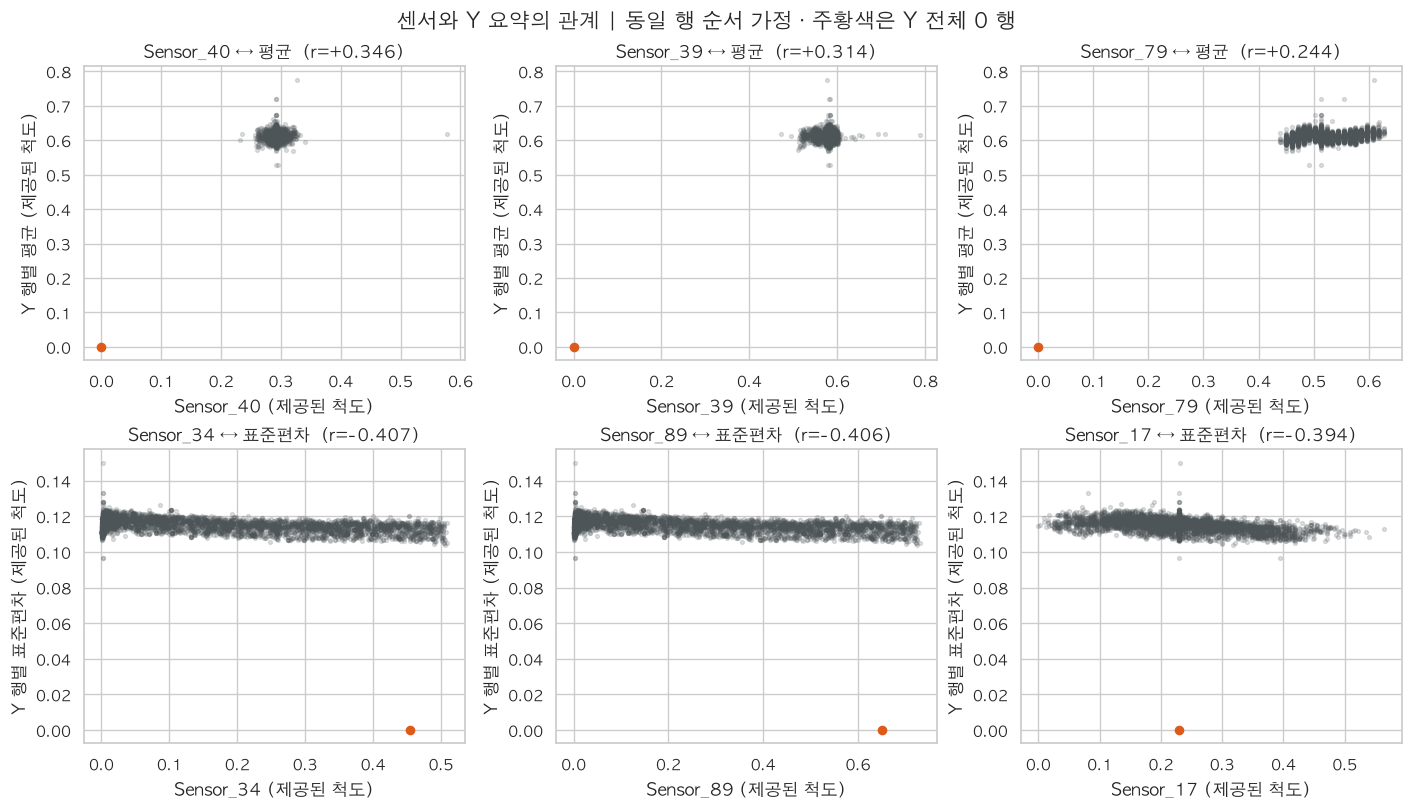

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for row, target in enumerate(targets):
    sensors = top_correlations(correlations, target, 3).index.tolist()
    for col, ax in enumerate(axes[row]):
        if col >= len(sensors):
            ax.set_visible(False); continue
        sensor = sensors[col]
        ax.scatter(analysis[sensor], analysis[target], s=8, alpha=.18, color='#4e5558', rasterized=True)
        if zero_y_mask.any():
            ax.scatter(analysis.loc[zero_y_mask, sensor], analysis.loc[zero_y_mask, target], s=35, color='#df5a18', zorder=3)
        ax.set_title(f'{sensor} ↔ {target}  (r={correlations.loc[sensor, target]:+.3f})')
        ax.set_xlabel(f'{sensor} (제공된 척도)')
        ax.set_ylabel(f'Y 행별 {target} (제공된 척도)')
fig.suptitle('센서와 Y 요약의 관계 | 동일 행 순서 가정 · 주황색은 Y 전체 0 행', fontsize=15)
plt.show()

### 13-2. 모든 Y 값이 0인 행의 영향 확인

**왜?** 아주 드문 행 하나가 상관계수와 센서 순위를 크게 바꿀 수 있습니다. 원본 분석은 그대로 두고, Y의 17개 값이 모두 0인 행을 제외한 **민감도 시나리오**를 별도로 계산합니다. 제외 결과가 더 정확하다고 가정하거나 해당 행을 오류로 판정하는 작업은 아닙니다.

In [9]:
nonzero = ~zero_y_mask.reset_index(drop=True)
sensitivity = pd.DataFrame({name: X.reset_index(drop=True).loc[nonzero].corrwith(
    analysis.loc[nonzero, name], method='pearson') for name in targets})
for target in targets:
    print(f'[{target}] 전체 행 포함: 상위 5개')
    display(top_correlations(correlations, target))
    print(f'[{target}] Y 전체 0 행 제외: 상위 5개 (민감도 비교)')
    display(top_correlations(sensitivity, target))
    print(f'상위 센서: {top_correlations(correlations, target).index[0]} → '
          f'{top_correlations(sensitivity, target).index[0]}')

[평균] 전체 행 포함: 상위 5개


,Pearson r
Sensor_40,0.3456
Sensor_39,0.3143
Sensor_79,0.2439
Sensor_80,0.1986
Sensor_33,-0.1827


[평균] Y 전체 0 행 제외: 상위 5개 (민감도 비교)


,Pearson r
Sensor_33,-0.2342
Sensor_80,0.2320
Sensor_8,0.2292
Sensor_50,-0.1865
Sensor_55,-0.1851


상위 센서: Sensor_40 → Sensor_33
[표준편차] 전체 행 포함: 상위 5개


,Pearson r
Sensor_34,-0.4066
Sensor_89,-0.4057
Sensor_17,-0.3944
Sensor_29,-0.3857
Sensor_27,-0.3812


[표준편차] Y 전체 0 행 제외: 상위 5개 (민감도 비교)


,Pearson r
Sensor_15,-0.4498
Sensor_34,-0.4377
Sensor_89,-0.4367
Sensor_17,-0.4366
Sensor_29,-0.4138


상위 센서: Sensor_34 → Sensor_15


## 14. 선택된 센서끼리의 관계

**왜?** 여러 센서가 비슷하게 움직이면 나중에 회귀모델에서 각 센서의 기여를 구분하기 어려울 수 있습니다. 평균과 표준편차 각각의 상위 5개 센서의 **합집합**만 선택해 서로의 Pearson 상관계수를 히트맵으로 봅니다. +1은 같은 방향, −1은 반대 방향으로 강하게 움직이는 관계입니다.

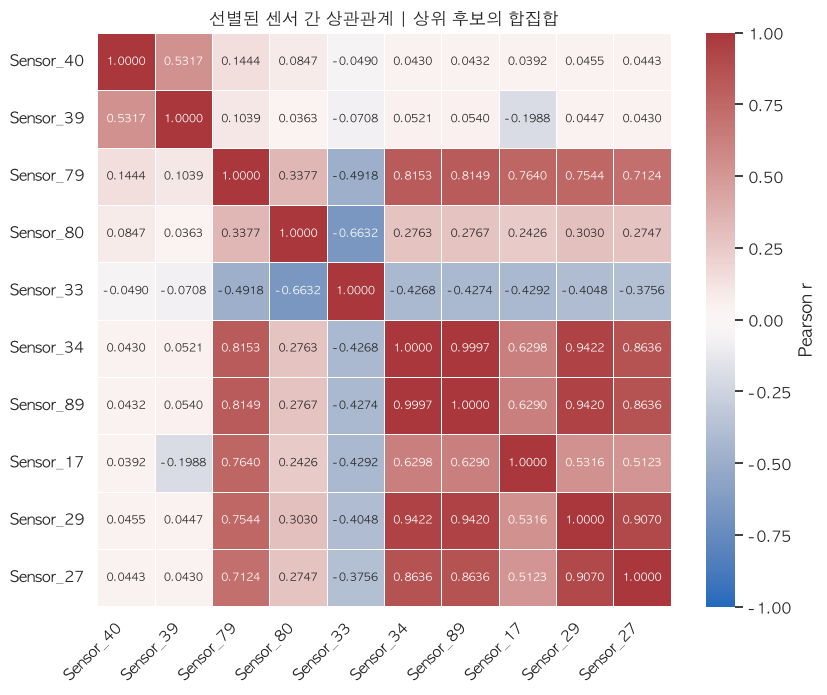

선별된 센서: Sensor_40, Sensor_39, Sensor_79, Sensor_80, Sensor_33, Sensor_34, Sensor_89, Sensor_17, Sensor_29, Sensor_27


In [10]:
selected_sensors = list(dict.fromkeys(
    sensor for target in targets for sensor in top_correlations(correlations, target).index
))
sensor_corr = X[selected_sensors].corr(method='pearson')
plt.figure(figsize=(max(7, len(selected_sensors) * .85), max(5.5, len(selected_sensors) * .7)))
sns.heatmap(sensor_corr, vmin=-1, vmax=1, center=0, cmap='vlag', annot=True, fmt='.4f', annot_kws={'size': 8},
            square=True, linewidths=.4, cbar_kws={'label': 'Pearson r'})
plt.title('선별된 센서 간 상관관계 | 상위 후보의 합집합')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
print('선별된 센서:', ', '.join(selected_sensors))

## 15. EDA 결과 정리와 다음 단계

아래 요약은 위에서 실제로 계산한 결과를 다시 읽어 정리합니다. 상관계수는 파일의 행 순서가 대응한다는 가정에 기반한 탐색 결과입니다.

In [11]:
x_const = list(X.columns[X.nunique(dropna=True) <= 1])
top_mean = top_correlations(correlations, '평균')
top_spread = top_correlations(correlations, '표준편차')
tri = sensor_corr.where(np.triu(np.ones(sensor_corr.shape), k=1).astype(bool))
pairs = tri.stack().sort_values(key=lambda s: s.abs(), ascending=False)
strongest_pair = pairs.index[0] if len(pairs) else None
lines = [
    f'- **데이터 상태:** X {len(X):,}행·{X.shape[1]}열, Y {len(Y):,}행·{Y.shape[1]}열. X/Y 원본 결측 셀은 각각 {int(X_raw.isna().sum().sum()):,}/{int(Y_raw.isna().sum().sum()):,}개, X 상수 열 {len(x_const)}개.',
    f'- **중복과 특이 행:** X/Y의 완전 중복 행은 각각 {int(X_raw.duplicated().sum()):,}/{int(Y_raw.duplicated().sum()):,}개. Y 전체가 0인 행은 {len(zero_y_indices)}개 (0부터 시작하는 인덱스 {zero_y_indices}).',
    f'- **Y 분포:** 행별 평균의 중앙값 {metrics["평균"].median():.4f}, 행별 표준편차의 중앙값 {metrics["표준편차"].median():.4f}, 범위의 중앙값 {metrics["범위"].median():.4f} (모두 제공된 척도).',
    f'- **평균과의 관계:** 전체 행 기준 가장 큰 절대 상관 후보는 {top_mean.index[0]} (r={top_mean.iloc[0, 0]:+.3f}); 0행 제외 시 {top_correlations(sensitivity, "평균").index[0]}.',
    f'- **표준편차와의 관계:** 전체 행 기준 후보는 {top_spread.index[0]} (r={top_spread.iloc[0, 0]:+.3f}); 0행 제외 시 {top_correlations(sensitivity, "표준편차").index[0]}.',
]
if strongest_pair:
    lines.append(f'- **선별 센서 사이:** 절대 상관이 가장 큰 쌍은 {strongest_pair[0]}·{strongest_pair[1]} (r={pairs.iloc[0]:+.6f}).')
lines += [
    '- **전처리:** 상수 센서는 상관·회귀 후보에서 제외하고, 중복 및 0행은 원인을 확인하기 전 유지합니다. 데이터 분할 뒤 전처리 규칙을 학습 데이터에 맞춥니다.',
    '- **다음 분석:** X·Y 행 대응과 Y 측정값의 단위·변환 방식을 원저자에게 확인합니다. 반복된 Y와 각 관측의 독립성도 확인하고 Lot·시간 정보가 있다면 이를 고려해 평가 데이터를 분리합니다. 이후 회귀모델을 평가하고, 실제 제어 가능한 설정값과 검증할 조건이 확보되면 Split 실험을 설계합니다.'
]
display(Markdown('\n'.join(lines)))

- **데이터 상태:** X 4,848행·97열, Y 4,848행·17열. X/Y 원본 결측 셀은 각각 0/0개, X 상수 열 0개.
- **중복과 특이 행:** X/Y의 완전 중복 행은 각각 0/1,203개. Y 전체가 0인 행은 1개 (0부터 시작하는 인덱스 [2586]).
- **Y 분포:** 행별 평균의 중앙값 0.6131, 행별 표준편차의 중앙값 0.1153, 범위의 중앙값 0.3825 (모두 제공된 척도).
- **평균과의 관계:** 전체 행 기준 가장 큰 절대 상관 후보는 Sensor_40 (r=+0.346); 0행 제외 시 Sensor_33.
- **표준편차와의 관계:** 전체 행 기준 후보는 Sensor_34 (r=-0.407); 0행 제외 시 Sensor_15.
- **선별 센서 사이:** 절대 상관이 가장 큰 쌍은 Sensor_34·Sensor_89 (r=+0.999660).
- **전처리:** 상수 센서는 상관·회귀 후보에서 제외하고, 중복 및 0행은 원인을 확인하기 전 유지합니다. 데이터 분할 뒤 전처리 규칙을 학습 데이터에 맞춥니다.
- **다음 분석:** X·Y 행 대응과 Y 측정값의 단위·변환 방식을 원저자에게 확인합니다. 반복된 Y와 각 관측의 독립성도 확인하고 Lot·시간 정보가 있다면 이를 고려해 평가 데이터를 분리합니다. 이후 회귀모델을 평가하고, 실제 제어 가능한 설정값과 검증할 조건이 확보되면 Split 실험을 설계합니다.